# Czy już umiemy odróżnić OK od NOK?
**Run All** przelicza modele na tym samym podziale po całych płytkach. Wybierz `.venv`.
Mamy 2 NOK i roboczo 3 OK. Foldery OK są różnymi płytkami **na podstawie przyjętego założenia**, nie potwierdzonych ID klienta.
Wynik jest obiecującą poszlaką. Sposób zapisu jest powiązany z klasą, więc nie wolno przenosić accuracy z tej paczki na fabrykę.

In [1]:
from pathlib import Path
import sys, json, io, contextlib
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/client_archive_manifest.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Otwórz folder ceramic-ping-lab w VS Code.")
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from pinglab.clientstudy import prepare, load, embeddings, recording_widget, OUT_REL
OUT = ROOT / OUT_REL
pd.set_option("display.max_colwidth", 65)
%matplotlib inline
print("Python:", sys.executable)
print("Wyniki:", OUT)


Python: /Users/karolsii/dev/ceramic-ping-lab/.venv/bin/python
Wyniki: /Users/karolsii/dev/ceramic-ping-lab/reports/runs/client-combined-20260929


## 1. Te same uderzenia dla każdej metody
Wybieramy 10 trafień równomiernie w czasie z każdego użytecznego pliku. AST tworzy embedding, czyli wektor 768 liczb. Wagi są zamrożone i już zapisane lokalnie. Nie uczymy transformera. AST pracuje przy 16 kHz, więc nie widzi pasma >8 kHz. 170 ms dopełnia standardowy procesor modelu.

In [2]:
with contextlib.redirect_stdout(io.StringIO()):
    recordings, candidates, features = prepare(ROOT)
    representations = embeddings(ROOT)
display(representations.groupby(["scope","group"]).agg(nagrania=("recording_id","nunique"),uderzenia=("event_id","size")))
print("Physics: 15 cech; MFCC: 26; mel: 40; AST: 768.")

nagrania  uderzenia
scope   group                            
chipped Bad_3_Bitten         3         30
        Bad_4_Bitten         3         30
core    Bad_1                4         40
        Bad_2                5         50
        OK_1                10        100
        OK_2                 3         30
        OK_3                 5         50

Physics: 15 cech; MFCC: 26; mel: 40; AST: 768.


## 2. Mapa podobieństwa
Każdy punkt to nagranie. Kolory: Bad_1 czerwony, Bad_2 pomarańczowy, OK_1 turkusowy, OK_2 niebieski, OK_3 zielony. Trójkąt: jedna podpora, koło: pozostałe. PCA streszcza wektor w 2 liczbach i służy tylko do oglądania. Model używa całego wektora; ta mapa nie mierzy accuracy.

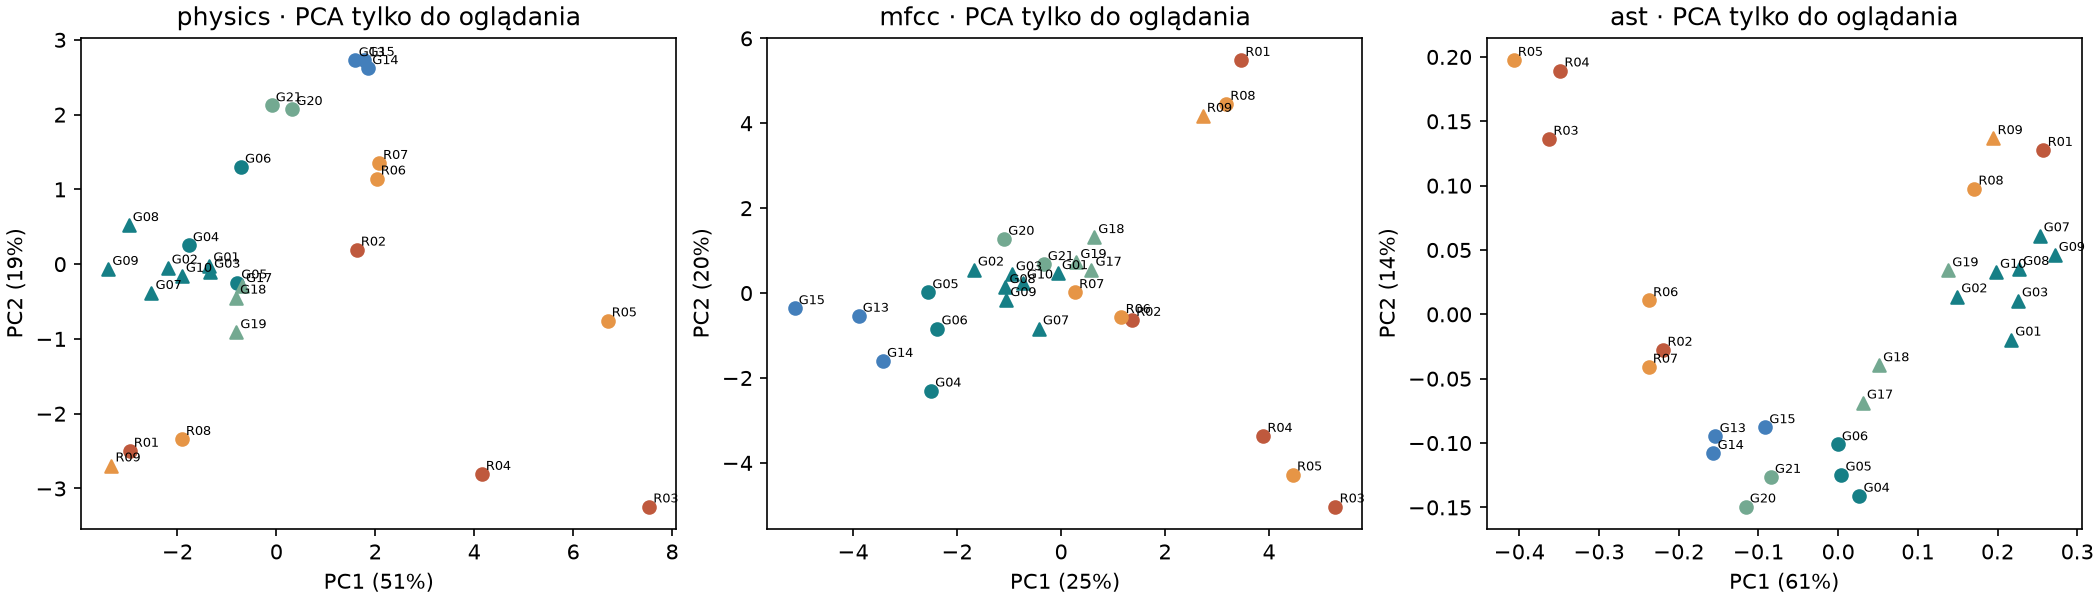

In [3]:
from pinglab.clientdiagnostics import figures
figures(ROOT)
display(Image(filename=str(OUT / "figures/pca.png")))

## 3. Trening i uczciwszy podział
6 prób: odkładamy całą jedną NOK i jedną OK. Żaden tap tej samej grupy nie przechodzi między treningiem i testem. Skaler uczy się wyłącznie na treningu. Stałe LR C=0.1 i płytki XGBoost, bez szukania najlepszych parametrów. Klasy i grupy mają równe wagi. Powtarzane próby nie są nowymi płytkami.

In [4]:
from pinglab.clientmodels import run
with contextlib.redirect_stdout(io.StringIO()):
    scores = run(ROOT)
audit = json.loads((OUT / "split_audit.json").read_text())
display(pd.DataFrame(audit)[["fold","train_groups","test_groups","train_taps","test_taps"]])

,fold,train_groups,test_groups,train_taps,test_taps
0,Bad_1__OK_1,"[Bad_2, OK_2, OK_3]","[Bad_1, OK_1]",130,140
1,Bad_1__OK_2,"[Bad_2, OK_1, OK_3]","[Bad_1, OK_2]",200,70
2,Bad_1__OK_3,"[Bad_2, OK_1, OK_2]","[Bad_1, OK_3]",180,90
3,Bad_2__OK_1,"[Bad_1, OK_2, OK_3]","[Bad_2, OK_1]",120,150
4,Bad_2__OK_2,"[Bad_1, OK_1, OK_3]","[Bad_2, OK_2]",190,80
5,Bad_2__OK_3,"[Bad_1, OK_1, OK_2]","[Bad_2, OK_3]",170,100


## 4. Porównanie modeli
**Accuracy**: ile decyzji jest poprawnych. **Recall NOK**: ile wadliwych wykryliśmy. **Fałszywe odrzucenia OK**: ile dobrych odrzuciliśmy. **Balanced accuracy** nadaje obu klasom równą wagę. **AUC** ocenia uporządkowanie wyników bez konkretnego progu. Próg 0.5 jest stały, a oceny nie są skalibrowanym prawdopodobieństwem wady.

Tabela nagrań uśrednia przewidywania ze wszystkich prób, w których dany plik był odłożony. W jednej próbie MFCC odrzuca jedno OK, choć po uśrednieniu tabela pokazuje 27/27. Poniżej są również osobne próby i tylko pięć zakładanych płytek.

In [5]:
cols = ["model","n","accuracy","balanced_accuracy","recall_nok","false_reject_ok","auc","tp","fn","tn","fp"]
display(scores[scores.level.eq("recording")][cols].round(3))
display(scores[scores.level.eq("assumed_plate")][cols].round(3))
folds = pd.read_csv(OUT / "fold_metrics.csv")
display(folds[folds.model.isin(["MFCC + LR","AST + LR"])].round(3))

,model,n,accuracy,balanced_accuracy,recall_nok,false_reject_ok,auc,tp,fn,tn,fp
0,AST + LR,27,0.926,0.917,0.889,0.056,0.994,8,1,17,1
1,AST + XGB,27,0.889,0.861,0.778,0.056,0.981,7,2,17,1
2,MFCC + LR,27,1.000,1.000,1.000,0.000,1.000,9,0,18,0
3,MFCC + XGB,27,0.963,0.944,0.889,0.000,1.000,8,1,18,0
4,QC no codec + LR,27,0.889,0.917,1.000,0.167,0.951,9,0,15,3
5,QC only + LR,27,0.926,0.889,0.778,0.000,0.969,7,2,18,0
6,mel + LR,27,0.963,0.972,1.000,0.056,1.000,9,0,17,1
7,physics + LR,27,0.630,0.639,0.667,0.389,0.790,6,3,11,7
8,physics + XGB,27,0.889,0.917,1.000,0.167,0.981,9,0,15,3
9,always OK,27,0.667,0.500,0.000,0.000,0.500,0,9,18,0


,model,n,accuracy,balanced_accuracy,recall_nok,false_reject_ok,auc,tp,fn,tn,fp
10,AST + LR,5,1.0,1.000,1.0,0.000,1.000,2,0,3,0
11,AST + XGB,5,1.0,1.000,1.0,0.000,1.000,2,0,3,0
12,MFCC + LR,5,1.0,1.000,1.0,0.000,1.000,2,0,3,0
13,MFCC + XGB,5,1.0,1.000,1.0,0.000,1.000,2,0,3,0
14,QC no codec + LR,5,1.0,1.000,1.0,0.000,1.000,2,0,3,0
15,QC only + LR,5,1.0,1.000,1.0,0.000,1.000,2,0,3,0
16,mel + LR,5,1.0,1.000,1.0,0.000,1.000,2,0,3,0
17,physics + LR,5,0.8,0.833,1.0,0.333,0.833,2,0,2,1
18,physics + XGB,5,1.0,1.000,1.0,0.000,1.000,2,0,3,0
19,always OK,5,0.6,0.500,0.0,0.000,0.500,0,2,3,0


,model,fold,n,n_nok,accuracy,balanced_accuracy,recall_nok,false_reject_ok,auc,tp,fn,tn,fp
0,AST + LR,Bad_1__OK_1,14,4,0.929,0.875,0.75,0.0,1.0,3,1,10,0
1,AST + LR,Bad_1__OK_2,7,4,0.857,0.875,0.75,0.0,1.0,3,1,3,0
2,AST + LR,Bad_1__OK_3,9,4,0.889,0.900,1.00,0.2,1.0,4,0,4,1
3,AST + LR,Bad_2__OK_1,15,5,0.933,0.900,0.80,0.0,1.0,4,1,10,0
4,AST + LR,Bad_2__OK_2,8,5,0.875,0.900,0.80,0.0,1.0,4,1,3,0
5,AST + LR,Bad_2__OK_3,10,5,1.000,1.000,1.00,0.0,1.0,5,0,5,0
12,MFCC + LR,Bad_1__OK_1,14,4,1.000,1.000,1.00,0.0,1.0,4,0,10,0
13,MFCC + LR,Bad_1__OK_2,7,4,1.000,1.000,1.00,0.0,1.0,4,0,3,0
14,MFCC + LR,Bad_1__OK_3,9,4,0.889,0.900,1.00,0.2,1.0,4,0,4,1
15,MFCC + LR,Bad_2__OK_1,15,5,1.000,1.000,1.00,0.0,1.0,5,0,10,0


## 5. Najważniejsza kontrola: czy rozpoznajemy sposób nagrywania?
QC-only używa długości, poziomu, ciszy i kodeka. QC-no-codec usuwa nawet informację o formacie. Ich wysokie wyniki ostrzegają przed myleniem właściwości płytek ze sposobem zbierania. Reguła AAC=NOK jest celowo prymitywna i nie analizuje widma.

Podzbiór 4 podpór usuwa część różnic stanowiska, ale pozostawia AAC po stronie NOK i WAV po stronie OK. Dwa NOK w WAV, R07/R08, też są rozpoznane przez MFCC; to poszlaka szerszego sygnału, nie rozwiązanie wszystkich zakłóceń.

In [6]:
display(pd.DataFrame([json.loads((OUT / "codec_control.json").read_text())]).round(3))
display(pd.read_csv(OUT / "matched_support_metrics.csv").query("level == 'recording'").round(3))
file_predictions = pd.read_csv(OUT / "oof_recordings.csv")
display(file_predictions.query("model == 'MFCC + LR' and recording_id in ['R07', 'R08']"))
perms = pd.read_csv(OUT / "group_label_permutations.csv")
print("Tylko", len(perms), "możliwych przydziałów etykiet; p dla AUC >= rzeczywistego:", (perms.auc >= 1-1e-12).mean())
display(pd.read_csv(OUT / "old_metrics_diagnostic.csv").round(3))
print("OLD: diagnostyka innych plików, nie potwierdzony test niezależnych płytek.")

,n,n_nok,accuracy,balanced_accuracy,recall_nok,false_reject_ok,auc,tp,fn,tn,fp
0,27,9,0.926,0.889,0.778,0.0,0.889,7,2,18,0


,level,model,n,n_nok,accuracy,balanced_accuracy,recall_nok,false_reject_ok,auc,tp,fn,tn,fp
0,recording,AST + LR,10,2,1.0,1.000,1.0,0.000,1.000,2,0,8,0
1,recording,MFCC + LR,10,2,1.0,1.000,1.0,0.000,1.000,2,0,8,0
2,recording,QC no codec + LR,10,2,0.9,0.938,1.0,0.125,1.000,2,0,7,1
3,recording,QC only + LR,10,2,1.0,1.000,1.0,0.000,1.000,2,0,8,0
4,recording,physics + LR,10,2,0.7,0.625,0.5,0.250,0.875,1,1,6,2
5,recording,always OK,10,2,0.8,0.500,0.0,0.000,0.500,0,2,8,0


,model,recording_id,group,label,score
78,MFCC + LR,R07,Bad_2,1,0.743258
79,MFCC + LR,R08,Bad_2,1,0.904151


Tylko 10 możliwych przydziałów etykiet; p dla AUC >= rzeczywistego: 0.1


,model,n,n_nok,accuracy,balanced_accuracy,recall_nok,false_reject_ok,auc,tp,fn,tn,fp
0,AST + LR,8,3,0.875,0.9,1.0,0.2,1.0,3,0,4,1
1,MFCC + LR,8,3,0.750,0.8,1.0,0.4,1.0,3,0,3,2
2,physics + LR,8,3,0.625,0.7,1.0,0.6,1.0,3,0,2,3


OLD: diagnostyka innych plików, nie potwierdzony test niezależnych płytek.


## 6. Szum: utrzymuje wykrywanie NOK, odrzuca więcej OK
Uczymy na oryginałach, zmieniamy tylko odłożone okna. SNR 20 dB jest słabszym szumem niż 10 dB. Używamy aktywnego fragmentu tła 19–30 s; wyciszoną część pomijamy. Test nie obejmuje ponownej detekcji uderzeń ani AST. Ściszenie powinno nie zmieniać wyniku dzięki normalizacji.

In [7]:
from pinglab.clientdiagnostics import perturbations
with contextlib.redirect_stdout(io.StringIO()):
    noise_results = perturbations(ROOT)
display(noise_results[["model","variant","accuracy","recall_nok","false_reject_ok","auc"]].round(3))

,model,variant,accuracy,recall_nok,false_reject_ok,auc
0,MFCC + LR,original,1.000,1.000,0.000,1.000
1,physics + LR,original,0.630,0.667,0.389,0.790
2,MFCC + LR,gain -12 dB,1.000,1.000,0.000,1.000
3,physics + LR,gain -12 dB,0.630,0.667,0.389,0.790
4,MFCC + LR,factory SNR 20 dB,0.815,1.000,0.278,1.000
5,physics + LR,factory SNR 20 dB,0.667,1.000,0.500,0.889
6,MFCC + LR,factory SNR 10 dB,0.778,1.000,0.333,0.969
7,physics + LR,factory SNR 10 dB,0.333,1.000,1.000,0.858


## 7. Ile uderzeń do decyzji?
Losujemy 1/3/5/10 z tych samych odłożonych uderzeń, 100 razy. Pokazujemy medianę ocen. Pasmo to zmienność losowania, nie pewność statystyczna na nowych płytkach. Bez pozycji trafień nie ocenimy, czy jedno konkretne uderzenie centralne wystarczy.

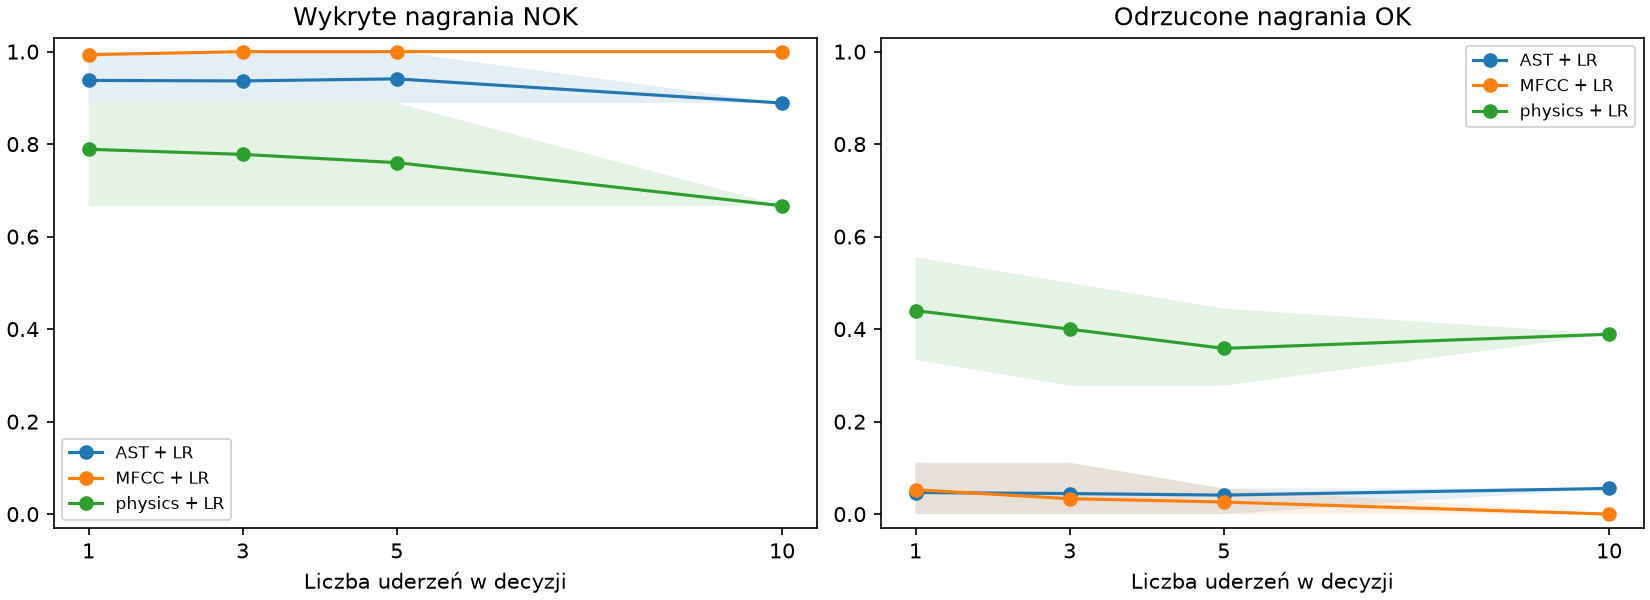

balanced_accuracy  recall_nok  false_reject_ok
model        k                                                 
AST + LR     1               0.946       0.938            0.047
             3               0.946       0.937            0.044
             5               0.950       0.941            0.041
             10              0.917       0.889            0.056
MFCC + LR    1               0.970       0.993            0.053
             3               0.983       1.000            0.033
             5               0.987       1.000            0.026
             10              1.000       1.000            0.000
physics + LR 1               0.674       0.789            0.440
             3               0.689       0.778            0.400
             5               0.701       0.760            0.358
             10              0.639       0.667            0.389

In [8]:
import importlib.util
spec = importlib.util.spec_from_file_location("combined_review", ROOT / "scripts/build_combined_review.py")
review = importlib.util.module_from_spec(spec)
spec.loader.exec_module(review)
review.performance_figures()
display(Image(filename=str(OUT / "figures/tap_count.png")))
taps = pd.read_csv(OUT / "tap_count_resampling.csv")
display(taps.groupby(["model","k"])[["balanced_accuracy","recall_nok","false_reject_ok"]].mean().round(3))

## 8. Decyzja po tej rundzie
**Kontynuować PoC.** MFCC jest dobrym prostym punktem odniesienia, AST jest dodatkową kontrolą. Największy zysk teraz da kontrolowana nowa sesja tych samych płytek z jednakowym zapisem oraz więcej fizycznych sztuk, szczególnie NOK. Nie dostrajamy progu do uzyskania zerowej liczby pomyłek na tych samych danych.

Pełny opis, zalecenia i atlas są w START.html. Surowe audio i wyniki pozostają lokalnie.

In [9]:
review.write_report()
print("Raport:", OUT / "START.html")
from datetime import datetime, timezone
verification = dict(notebook="models", finished_utc=datetime.now(timezone.utc).isoformat(), python=sys.executable)
(OUT / "last_run_models.json").write_text(json.dumps(verification, indent=2))
print("GOTOWE — models: wszystkie komórki zakończone.")

Raport: /Users/karolsii/dev/ceramic-ping-lab/reports/runs/client-combined-20260929/START.html
GOTOWE — models: wszystkie komórki zakończone.
